# Task 2: Data Preparation and Analysis


## 1. Introduction

This section uses Python to prepare and analyse the healthcare insurance dataset. The aim is to identify patterns in insurance charges and explore relationships between customer characteristics and insurance costs.

In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

The healthcare insurance dataset is loaded into Python using Pandas.

In [2]:

from pathlib import Path

# Construct the file path
file_path = Path.cwd().parent / "project_data" / "insurance_raw_data.csv"

try:
    # Attempt to load the dataset
    insurance_df = pd.read_csv(file_path)
    print(f"Dataset loaded successfully!\nFile location: {file_path}")
except FileNotFoundError:
    print(f"Error: Dataset not found at {file_path}")
    raise

Dataset loaded successfully!
File location: c:\Users\zainab\Desktop\data analysis course\Healthcare_insurance_project\project_data\insurance_raw_data.csv


In [3]:
# Display the first five record

insurance_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Initial Data Exploration

Initial data exploration helps us understand the dataset, its structure, variables and data quality before performing analysis.

In [4]:
# find the size of the dataset

rows, columns = insurance_df.shape

print("Number of rows: ", rows)
print("Number of columns: ", columns)

Number of rows:  1338
Number of columns:  7


In [5]:
# Display the columns names

print("Dataset columns are: ")

for column in insurance_df.columns:
    print("-", column)

Dataset columns are: 
- age
- sex
- bmi
- children
- smoker
- region
- charges


In [6]:
# check the initial information of each variable

insurance_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
# Count missing values in each column

missing_values = insurance_df.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [8]:
# Count duplicate records

duplicate_count = insurance_df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 1


In [9]:
# Create a list of the categorical columns you want to check
categorical_columns = ["sex", "smoker", "region"]

# Loop through each column in the list
for col in categorical_columns:
    print(f"--- {col} ---")
    print(insurance_df[col].value_counts(dropna=False))
    print()  # Add an empty line for spacing

--- sex ---
sex
male      676
female    662
Name: count, dtype: int64

--- smoker ---
smoker
no     1064
yes     274
Name: count, dtype: int64

--- region ---
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64



In [10]:
# Generate descriptive statistics

insurance_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
# Generate descriptive statistics for all columns

insurance_df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [12]:
# Check for unusual or potentially invalid values

print("Age values less than or equal to zero:",
      (insurance_df["age"] <= 0).sum())

print("BMI values less than or equal to zero:",
      (insurance_df["bmi"] <= 0).sum())

print("Negative number of children:",
      (insurance_df["children"] < 0).sum())

print("Negative insurance charges:",
      (insurance_df["charges"] < 0).sum())

Age values less than or equal to zero: 0
BMI values less than or equal to zero: 0
Negative number of children: 0
Negative insurance charges: 0


In [13]:
# Check for leading or trailing spaces in categorical columns

for col in categorical_columns:
    spaces = insurance_df[col].astype("string").str.strip().ne(
        insurance_df[col].astype("string")
    ).sum()

    print(f"{col}: {spaces} values with extra spaces")

sex: 0 values with extra spaces
smoker: 0 values with extra spaces
region: 0 values with extra spaces


In [14]:
# Create a basic inspection report

report_of_finding = pd.DataFrame({
    "Column": insurance_df.columns,
    "Data Type": insurance_df.dtypes.astype(str).values,
    "Missing Values": insurance_df.isnull().sum().values,
    "Unique Values": insurance_df.nunique().values
})

report_of_finding



,Column,Data Type,Missing Values,Unique Values
0,age,int64,0,47
1,sex,object,0,2
2,bmi,float64,0,548
3,children,int64,0,6
4,smoker,object,0,2
5,region,object,0,4
6,charges,float64,0,1337


## 4. Data Cleaning and Preparation

Data cleaning is an important stage of data analysis. It helps improve data quality and ensures that the dataset is suitable for further analysis.

A copy of the original dataset will be created so that the raw data remains unchanged.

In [15]:
# Create a copy of the original dataset

cleaned_df = insurance_df.copy()


### 4.1 Checking Categorical Data

In [16]:
# Check unique categorical values

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(cleaned_df[col].unique())
    


Unique values in sex:
['female' 'male']

Unique values in smoker:
['yes' 'no']

Unique values in region:
['southwest' 'southeast' 'northwest' 'northeast']



The categorical variables were checked to identify inconsistent or unexpected values.

The dataset contains two categories for sex (female and male), two categories for smoking status (yes and no), and four geographical regions (southwest, southeast, northwest and northeast).

No unexpected categories or spelling inconsistencies were identified. Therefore, no changes to these categorical values were required.

### 4.2 Handling Duplicate Records

In [17]:
# Display exact duplicate records

duplicates = cleaned_df[
    cleaned_df.duplicated(keep=False)
]

print(duplicates)

     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631


In [18]:
# Compare dataset size before and after duplicate removal

print("Rows before removing duplicates:", len(cleaned_df))

print("Rows after removing duplicates:",
      len(cleaned_df.drop_duplicates()))

Rows before removing duplicates: 1338
Rows after removing duplicates: 1337


In [19]:
duplicates = cleaned_df[
    cleaned_df.duplicated(keep=False)
]

display(duplicates)

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [20]:
# Remove exact duplicate records

cleaned_df = cleaned_df.drop_duplicates()

# Check the dataset size after removing duplicates

print("Original dataset rows:", len(insurance_df))
print("Cleaned dataset rows:", len(cleaned_df))
print("Remaining duplicate records:", cleaned_df.duplicated().sum())

Original dataset rows: 1338
Cleaned dataset rows: 1337
Remaining duplicate records: 0



During data inspection, one exact duplicate record was identified.

The two records contained identical values across all seven columns. Since the dataset does not include a unique customer identifier, it is not possible to confirm whether they represent the same individual.

For this analysis, one duplicate row was removed to prevent identical records from being counted twice. This decision is documented as a data limitation.

### 4.3 Check numerical data types

In [35]:
# Check the data types of numerical variables

numerical_columns = ["age", "bmi", "children", "charges"]

print("Data types of numerical variables:")
print(cleaned_df[numerical_columns].dtypes)

Data types of numerical variables:
age           int64
bmi         float64
children      int64
charges     float64
dtype: object



The numerical variables were examined to check their data types and identify any unusual or invalid values.

The dataset contains four numerical variables: age, BMI, children and insurance charges.

These variables will be checked to ensure that they contain appropriate values before statistical analysis is performed.

In [36]:

# Check for potentially invalid numerical values

print("Age less than or equal to zero:",
      (cleaned_df["age"] <= 0).sum())

print("BMI less than or equal to zero:",
      (cleaned_df["bmi"] <= 0).sum())

print("Negative number of children:",
      (cleaned_df["children"] < 0).sum())

print("Negative insurance charges:",
      (cleaned_df["charges"] < 0).sum())

Age less than or equal to zero: 0
BMI less than or equal to zero: 0
Negative number of children: 0
Negative insurance charges: 0


In [37]:
# Display minimum and maximum values for numerical variables

numerical_summary = cleaned_df[numerical_columns].agg(
    ["min", "max"]
)

display(numerical_summary)

,age,bmi,children,charges
min,18,15.96,0,1121.87390
max,64,53.13,5,63770.42801


In [38]:
# Calculate descriptive statistics

display(cleaned_df[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


### Numerical Data Inspection and Statistical Summary

The numerical variables were examined to check their data types and identify invalid values.

The dataset contains four numerical variables: age, BMI, children and insurance charges. All variables have appropriate numerical data types.

No invalid values were identified. There were no ages or BMI values less than or equal to zero, no negative numbers of children and no negative insurance charges.

After removing the exact duplicate record, the dataset contained 1,337 records.

The average age was approximately 39.22 years, while the average BMI was 30.66. The average number of children was approximately 1.10.

The mean insurance charge was 13,279.12, compared with a median of 9,386.16. The difference between the mean and median suggests that some individuals may have considerably higher insurance charges than others.

These findings will be investigated further through statistical comparisons and visualisations.

## 5. Statistical Analysis

Statistical analysis is used to identify patterns and differences in healthcare insurance charges.

The analysis will examine average and median charges, customer characteristics and differences between smoking groups and geographical regions.

In [25]:
# Calculate overall insurance charge statistics

print("Mean insurance charge:",
      cleaned_df["charges"].mean())

print("Median insurance charge:",
      cleaned_df["charges"].median())

print("Minimum insurance charge:",
      cleaned_df["charges"].min())

print("Maximum insurance charge:",
      cleaned_df["charges"].max())

print("Standard deviation:",
      cleaned_df["charges"].std())

Mean insurance charge: 13279.121486655948
Median insurance charge: 9386.1613
Minimum insurance charge: 1121.8739
Maximum insurance charge: 63770.42801
Standard deviation: 12110.359656344175


In [26]:
# Compare insurance charges by smoking status

smoking_analysis = cleaned_df.groupby("smoker")["charges"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

display(smoking_analysis)

,count,mean,median,min,max,std
smoker,,,,,,
no,1063,8440.660307,7345.72660,1121.8739,36910.60803,5992.973800
yes,274,32050.231832,34456.34845,12829.4551,63770.42801,11541.547176



The dataset was grouped by smoking status to compare insurance charges between smokers and non-smokers.

The results show that the average insurance charge for smokers was 32,050.23, compared with 8,440.66 for non-smokers.

This means that the average charge for smokers was approximately 3.8 times higher than for non-smokers.

The median charge was also considerably higher for smokers (34,456.35) than for non-smokers (7,345.73).

These findings suggest a strong association between smoking status and insurance charges in this dataset. However, this comparison does not prove that smoking directly causes higher charges, as other factors may also influence insurance costs.

In [27]:
# Compare insurance charges by geographical region

region_analysis = cleaned_df.groupby("region")["charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(region_analysis)

,count,mean,median,min,max
region,,,,,
northeast,324,13406.384516,10057.652025,1694.7964,58571.07448
northwest,324,12450.840844,8976.977250,1621.3402,60021.39897
southeast,364,14735.411438,9294.131950,1121.8739,63770.42801
southwest,325,12346.937377,8798.593000,1241.5650,52590.82939



The dataset was grouped by geographical region to compare insurance charges.

The Southeast region had the highest average insurance charge at 14,735.41, while the Southwest region had the lowest average at 12,346.94.

The Northeast region had the highest median charge at 10,057.65, followed by the Southeast region at 9,294.13.

In all four regions, the mean charge was higher than the median charge. This suggests that some individuals had considerably higher insurance charges than others.

These results indicate differences in insurance charges across geographical regions. However, further analysis is needed to understand whether other factors, such as age, BMI and smoking status, contribute to these differences.

In [28]:
cleaned_df["bmi_category"] = pd.cut(
    cleaned_df["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

bmi_analysis = cleaned_df.groupby(
    "bmi_category",
    observed=True
)["charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(bmi_analysis)

,count,mean,median,min,max
bmi_category,,,,,
Underweight,21,8657.620652,6640.544850,1621.3402,32734.18630
Normal,226,10435.440719,8604.153525,1121.8739,35069.37452
Overweight,386,10997.803881,8659.378000,1252.4070,38245.59327
Obese,704,15580.700985,10003.654500,1131.5066,63770.42801




BMI values were divided into four categories: Underweight, Normal, Overweight and Obese.

The results show that the Obese category had the highest average insurance charge at 15,580.70, while the Underweight category had the lowest average at 8,657.62.

The Obese category also contained the largest number of individuals, with 704 records.

The findings suggest that higher BMI categories may be associated with higher insurance charges. However, the relationship is not necessarily linear, and other factors, particularly smoking status and age, may also influence insurance costs.

The Underweight category contained only 21 individuals, so its results should be interpreted with caution.

In [29]:
age_analysis = cleaned_df["age"].corr(cleaned_df["charges"])
bmi_analysis = cleaned_df["bmi"].corr(cleaned_df["charges"])

print("Correlation between age and charges:", age_analysis)
print("Correlation between BMI and charges:", bmi_analysis)

Correlation between age and charges: 0.2983082125097864
Correlation between BMI and charges: 0.19840083122624938


In [30]:
print(
    "Correlation between BMI and Charges:",
    cleaned_df["bmi"].corr(cleaned_df["charges"])
)

print(
    "Correlation between Age and Charges:",
    cleaned_df["age"].corr(cleaned_df["charges"])
)

Correlation between BMI and Charges: 0.19840083122624938
Correlation between Age and Charges: 0.2983082125097864



Pearson correlation analysis was used to investigate the linear relationships between age, BMI and insurance charges.

The correlation coefficient between age and insurance charges was 0.2983, indicating a weak positive linear relationship. This suggests that insurance charges tend to increase as age increases.

The correlation coefficient between BMI and insurance charges was 0.1984, also indicating a weak positive linear relationship.

Age showed a stronger correlation with insurance charges than BMI in this dataset.

Although both variables showed positive relationships with insurance charges, the correlations were relatively weak. This suggests that other factors may also contribute to differences in insurance costs.

Correlation does not establish causation. Further analysis, including smoking status and other variables, is required to understand these relationships more fully.

## 5. Data Visualisation

### 5.1 Distribution of Insurance Charges

A histogram was created to examine the distribution of insurance charges and identify where most values are concentrated.

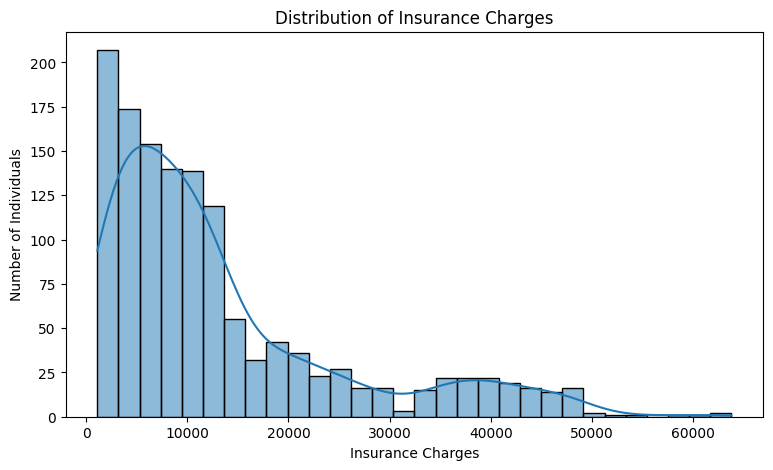

In [39]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=cleaned_df,
    x="charges",
    bins=30,
    kde=True
)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Number of Individuals")

plt.show()

The histogram shows that insurance charges are right-skewed. Most individuals have lower insurance charges, while a smaller number have substantially higher charges, creating a long tail on the right side of the distribution.

This pattern is consistent with the mean insurance charge being higher than the median. The histogram also indicates that insurance charges vary considerably across individuals.

### 5.2 Insurance Charges by Smoking Status

A box plot was created to compare the distribution of insurance charges between smokers and non-smokers. The plot helps compare the median, spread and potential outliers in each group.

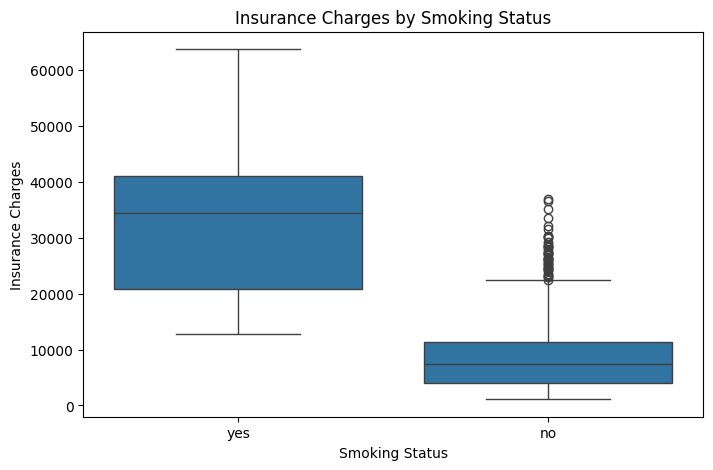

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=cleaned_df,
    x="smoker",
    y="charges"
)

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges")

plt.show()

The box plot shows a clear difference in insurance charges between smokers and non-smokers. Smokers have a substantially higher median charge, and their overall distribution is shifted towards higher costs.

Several potential outliers appear among non-smokers, representing individuals with unusually high charges compared with the rest of that group. These values should not automatically be removed, as they may be valid observations.

The visual pattern is consistent with the statistical comparison, which found a much higher average charge for smokers. This indicates an association between smoking status and insurance charges, but does not establish causation.

### 5.3 Average Insurance Charges by Region

A bar chart was created to compare the average insurance charges across the four geographical regions.

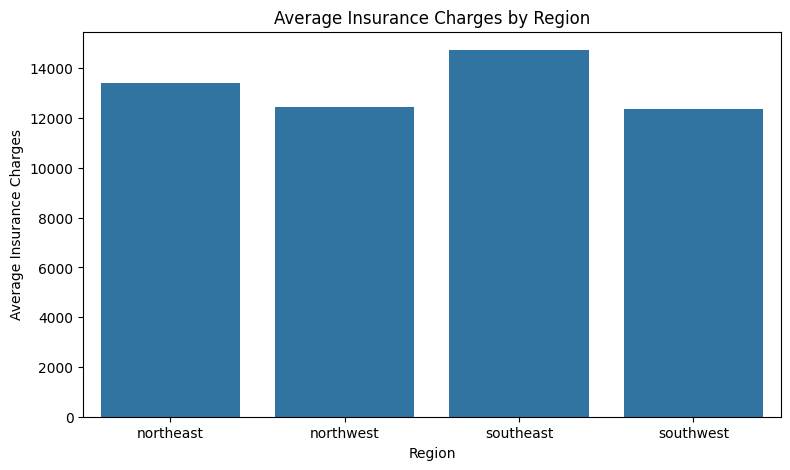

In [41]:
region_mean = cleaned_df.groupby("region")["charges"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_mean,
    x="region",
    y="charges"
)

plt.title("Average Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Insurance Charges")

plt.show()